# `fft` Tutorial

> Part of *PHYS 0241: Biomedical Imaging* (Prof. Michael E. Durst, Middlebury College). The [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/other/fft_tutorial.html) shows the rendered version together with the pre-rendered animations (course password required).
>
> **Start here:** no setup is needed for this notebook. In Google Colab, choose **File > Save a copy in Drive** to keep your changes.
>
> *Provided for academic use in PHYS 0241; please do not repost or redistribute ([terms of use](https://github.com/durstme/textbook-biomedicalimaging-notebooks/blob/main/LICENSE.md)).*

## Fourier transform with `fft` and `fftshift`

### Analytic Approach ###
Consider a signal $f(t)$ as a function of time which is just the sum of two sine curves with different frequencies:
$$s(t) = A_1 \sin(2\pi f_1 t) + A_2 \sin(2\pi f_2 t)$$
where $f_1$ = 5 Hz, $f_2$ = 50 Hz, $A_1$ = 3, $A_2$ = 1.5 (amplitudes unitless).

The Fourier transform $S(f)$ yields a plot of the amplitudes of the frequencies contained in the signal. Analytically, the Fourier transform is given by:
$$S(f) = \int_{-\infty}^{\infty} s(t) e^{-i 2\pi f t} dt$$
For this particular $s(t)$, we know that the result is delta function spikes at 5 Hz and at 50 Hz (as well as the corresponding negative frequency values), which means that we expect a Fourier transform to have four spikes in the frequency domain.

### Numerical Approach

The Fourier transform is an integral which assumes that the function is well defined.  What if you wanted to take the Fourier transform of a list of values?  We will use the **discrete Fourier transform (DFT)**.  For a sequence of $N$ values of a signal $x[n]$, the DFT produces the frequency-domain coefficients $X[k]$:

$$X(f) = \sum_{n=0}^{N-1} x[n] \cdot e^{-i (2\pi f) \cdot (n \Delta t)}$$

where $x[n]$ is the $n$-th sample of the signal in time, $X[f]$ is the Fourier transform coefficient, $N$ is the total number of points in the signal, and $n$ is an index value for a particular signal value.  The original signal spans a total time window $T$ and has spacing between points in time $\Delta t$, and the actual time for any $n$-th value is $t = n\cdot \Delta t$.

One can quickly plot $X(f)$, but what are the corresponding frequency coordinates?  The corresponding spacing in frequency is given by $\Delta f = 1/T = 1/(N\Delta t)$, and the total range of frequencies spans $f=-1/(2\Delta t)$ to $f=1/(2\Delta t)$, where $f_s = 1/\Delta t$ is known as the sampling frequency.

To implement a numerical Fourier transform, the **fast Fourier transform (FFT)** is a screamingly fast algorithm for calculating the DFT.  Going forward, we will use numpy's `fft`.  The challenge is that the frequency components are not output in numerical order but instead from $f=0$ to $f=1/(2\Delta t)$ followed by $f=-1/(2\Delta t)$ to $f=0$.  This means that any visualization or math done to the Fourier transform must re-center the frequencies first.  The can be done with the built-in function `fftshift`.

To take the Fourier Transform in the forward direction (time $\to$ frequency), we need to follow this order:
1. **Apply `fft`**: Compute the raw Discrete Fourier Transform.
   - `fft_raw = np.fft.fft(signal)`
   - *Note: Result has DC or $f=0$ at index 0 in the list.*
2. **Apply `fftshift`**: Move the zero-frequency (DC) component to the center of the array.
   - `fft_centered = np.fft.fftshift(fft_raw)`
3. **Generate Frequencies**: Use `fftfreq` and `fftshift` to get the matching x-axis.
   - `freq = np.fft.fftshift(np.fft.fftfreq(N, d=1/Fs))`

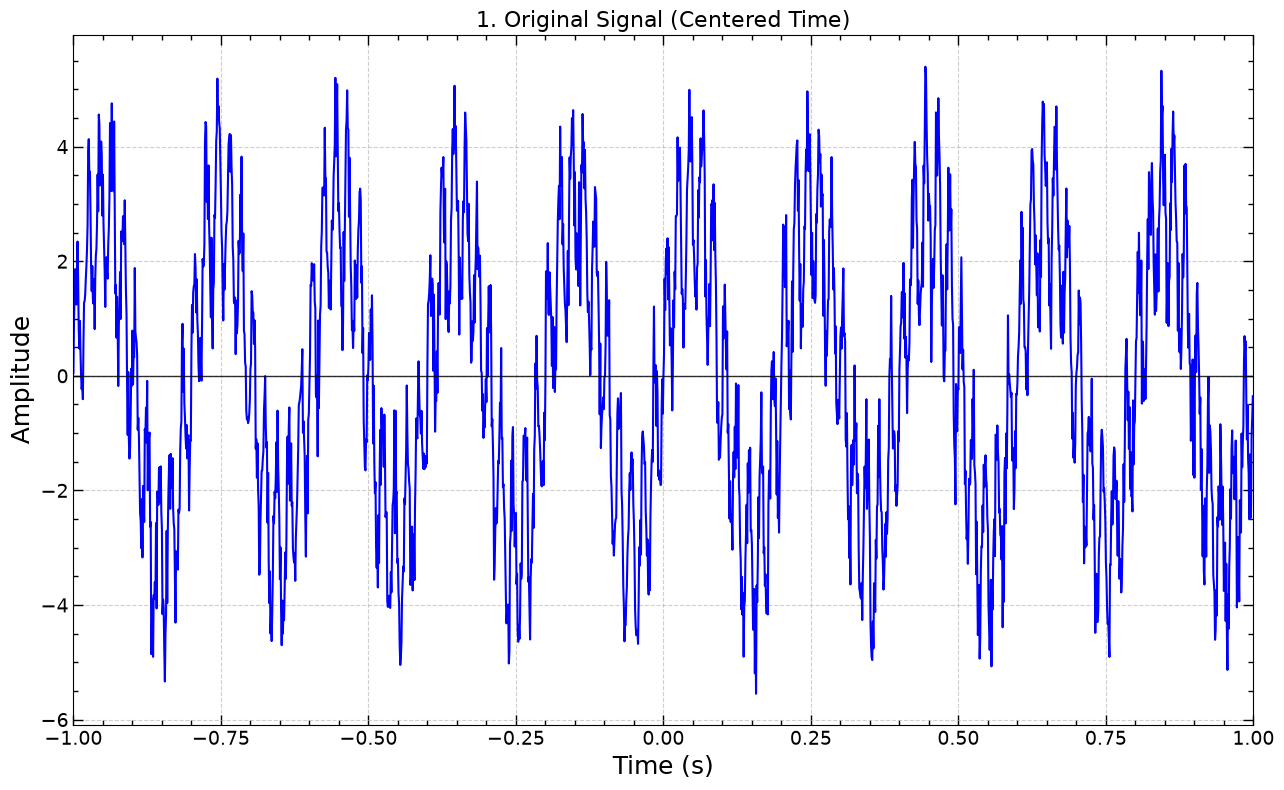

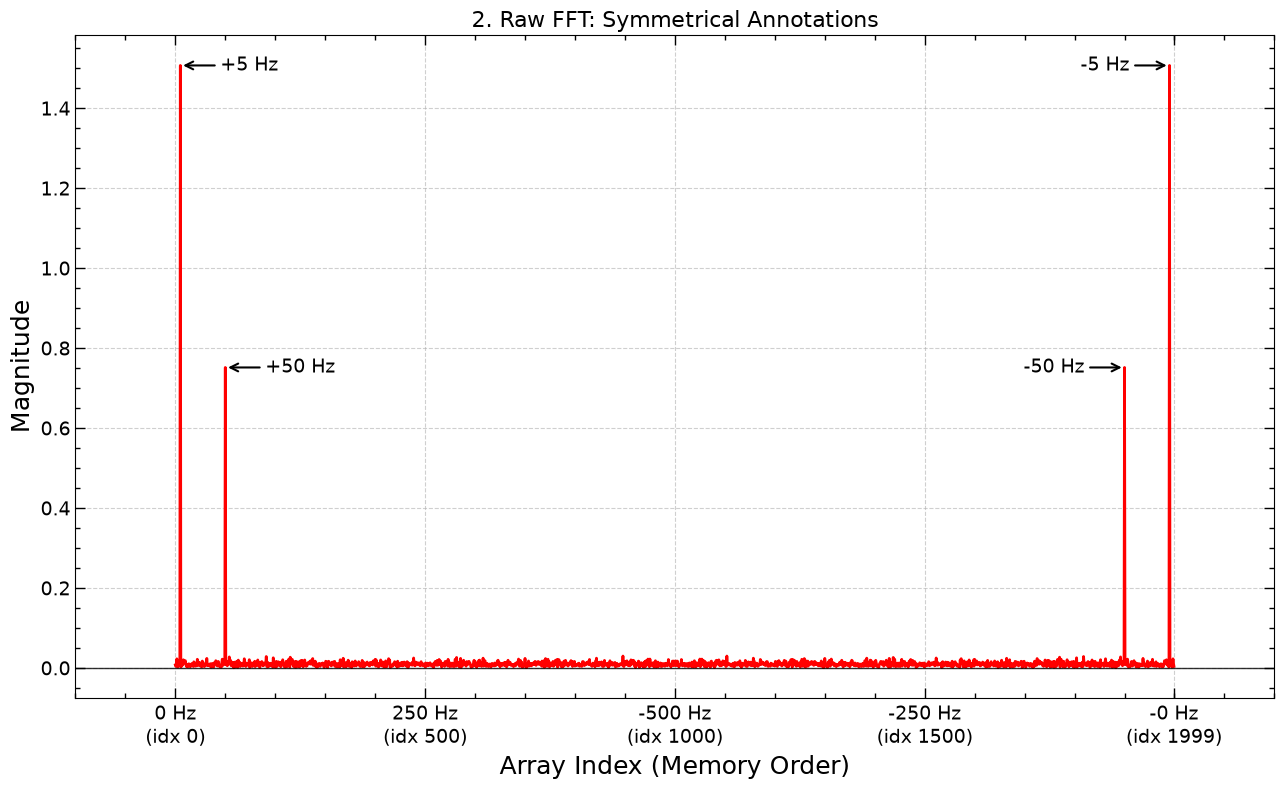

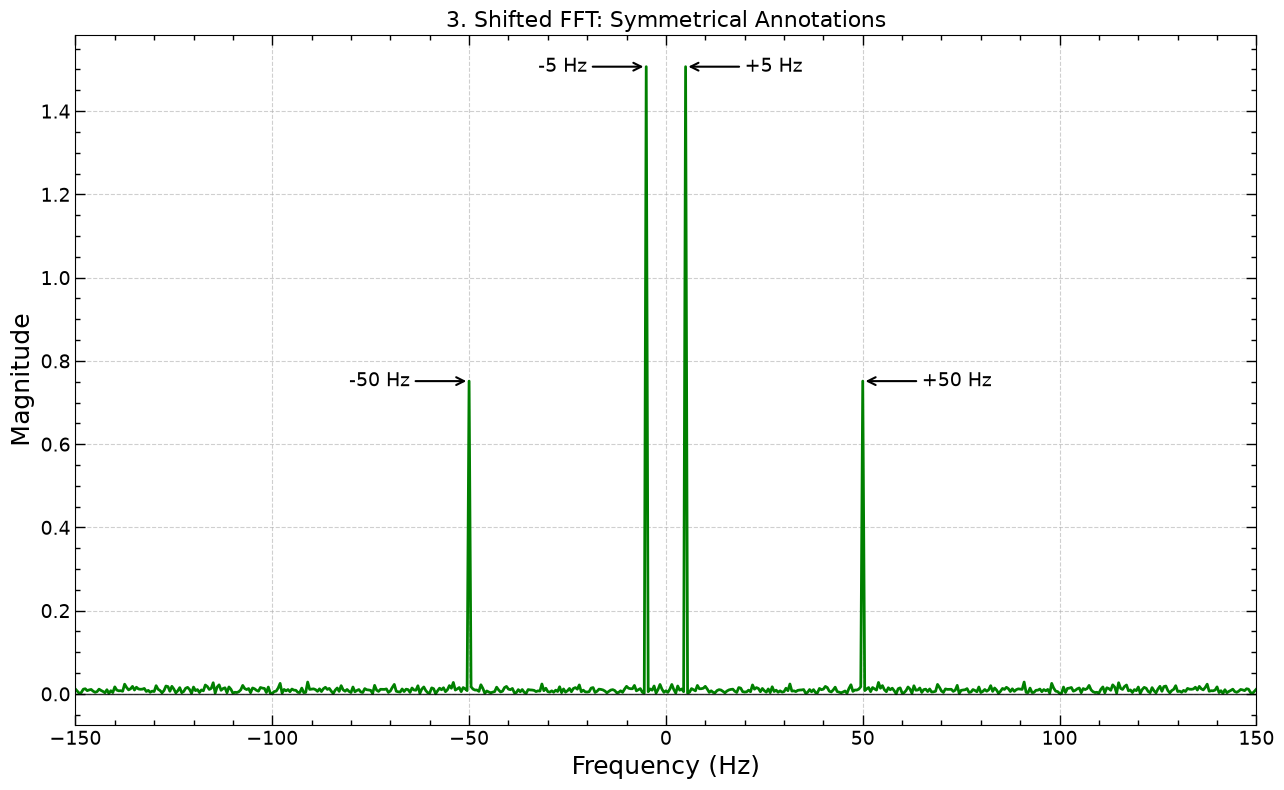

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Style Configuration ---
def apply_custom_style(ax, xlabel, ylabel, title=""):
    ax.minorticks_on()
    ax.tick_params(which='both', direction="in", width=1, labelsize=14)
    ax.tick_params(which='major', length=7)
    ax.tick_params(which='minor', length=3.5)
    ax.xaxis.set_ticks_position('both')
    ax.yaxis.set_ticks_position('both')
    
    ax.set_xlabel(xlabel, fontsize=18)
    ax.set_ylabel(ylabel, fontsize=18)
    if title:
        ax.set_title(title, fontsize=16)
    
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.axhline(0, color='black', linewidth=1, alpha=0.8)

# --- 2. Signal Generation (Centered Time Range) ---
Fs = 1000           
T = 2.0             
N = int(Fs * T)     
# Time vector from -1.0 to 1.0
t = np.linspace(-T/2, T/2, N, endpoint=False)

freq1, amp1 = 5, 3.0
freq2, amp2 = 50, 1.5
# Note: We use the same frequencies; the shift in 't' just shifts the phase
signal = amp1 * np.sin(2 * np.pi * freq1 * t) + \
         amp2 * np.sin(2 * np.pi * freq2 * t) + \
         0.5 * np.random.randn(N)

# --- 3. FFT Processing ---
fft_raw = np.fft.fft(signal)
fft_mag = np.abs(fft_raw) / N
freq_raw = np.fft.fftfreq(N, d=1/Fs)

# Pre-calculate shifted versions for plotting
fft_shifted = np.fft.fftshift(fft_mag)
fft_complex_shifted = np.fft.fftshift(fft_raw)
freq_shifted = np.fft.fftshift(freq_raw)

# Indices for annotations (The math remains the same for frequency spikes)
idx5 = int(freq1 * T)
idx50 = int(freq2 * T)
idxNeg5 = N - idx5
idxNeg50 = N - idx50

# --- 4. Plotting ---

# Plot 1: Original Signal in Time Domain
fig1, ax1 = plt.subplots(figsize=(8*1.618, 8))
ax1.plot(t, signal, color='blue', linewidth=1.5)
apply_custom_style(ax1, 'Time (s)', 'Amplitude', '1. Original Signal (Centered Time)')
ax1.set_xlim(-T/2, T/2)
fig1.tight_layout()

# Plot 2: Raw FFT (Index-based)
fig2, ax2 = plt.subplots(figsize=(8*1.618, 8))
ax2.plot(np.arange(N), fft_mag, color='red', linewidth=2)

arrow_props = dict(arrowstyle='->', lw=1.5, color='black')
font_cfg = {'fontsize': 14}

# Annotate Positive frequencies: Text on RIGHT, arrow points LEFT
ax2.annotate(f'+{freq1} Hz', xy=(idx5, fft_mag[idx5]), xytext=(idx5 + 80, fft_mag[idx5]),
             arrowprops=arrow_props, va='center', ha='left', **font_cfg)
ax2.annotate(f'+{freq2} Hz', xy=(idx50, fft_mag[idx50]), xytext=(idx50 + 80, fft_mag[idx50]),
             arrowprops=arrow_props, va='center', ha='left', **font_cfg)

# Annotate Negative frequencies: Text on LEFT, arrow points RIGHT
ax2.annotate(f'-{freq1} Hz', xy=(idxNeg5, fft_mag[idxNeg5]), xytext=(idxNeg5 - 80, fft_mag[idxNeg5]),
             arrowprops=arrow_props, va='center', ha='right', **font_cfg)
ax2.annotate(f'-{freq2} Hz', xy=(idxNeg50, fft_mag[idxNeg50]), xytext=(idxNeg50 - 80, fft_mag[idxNeg50]),
             arrowprops=arrow_props, va='center', ha='right', **font_cfg)

# Manual Ticks for Memory Index
tick_indices = [0, N//4, N//2, 3*N//4, N-1]
tick_labels = [f"{freq_raw[i]:.0f} Hz\n(idx {i})" for i in tick_indices]
ax2.set_xticks(tick_indices)
ax2.set_xticklabels(tick_labels)

ax2.set_xlim(-200, N + 200)
apply_custom_style(ax2, 'Array Index (Memory Order)', 'Magnitude', '2. Raw FFT: Symmetrical Annotations')
fig2.tight_layout()

# Plot 3: Shifted FFT (Frequency-based)
fig3, ax3 = plt.subplots(figsize=(8*1.618, 8))
ax3.plot(freq_shifted, fft_shifted, color='green', linewidth=2)

# Annotate Positive frequencies in shifted plot
ax3.annotate(f'+{freq1} Hz', xy=(freq1, fft_mag[idx5]), xytext=(freq1 + 15, fft_mag[idx5]),
             arrowprops=arrow_props, va='center', ha='left', **font_cfg)
ax3.annotate(f'+{freq2} Hz', xy=(freq2, fft_mag[idx50]), xytext=(freq2 + 15, fft_mag[idx50]),
             arrowprops=arrow_props, va='center', ha='left', **font_cfg)

# Annotate Negative frequencies in shifted plot
ax3.annotate(f'-{freq1} Hz', xy=(-freq1, fft_mag[idxNeg5]), xytext=(-freq1 - 15, fft_mag[idxNeg5]),
             arrowprops=arrow_props, va='center', ha='right', **font_cfg)
ax3.annotate(f'-{freq2} Hz', xy=(-freq2, fft_mag[idxNeg50]), xytext=(-freq2 - 15, fft_mag[idxNeg50]),
             arrowprops=arrow_props, va='center', ha='right', **font_cfg)

ax3.set_xlim(-150, 150) 
apply_custom_style(ax3, 'Frequency (Hz)', 'Magnitude', '3. Shifted FFT: Symmetrical Annotations')
fig3.tight_layout()

plt.show()

## Inverse Fourier Transform with `ifft` and `ifftshift`


To apply the inverse Fourier transform (frequency $\to$ time), we must first move the $f=0$ back to the first position in the array with `ifftshift`:
1. **Apply `ifftshift`**: Move the zero-frequency component back from the center to index 0.
   - **Crucial:** This is the inverse order of the forward Fourier transform.
   - `ready_for_ifft = np.fft.ifftshift(fft_centered)`
2. **Apply `ifft`**: Compute the Inverse Fast Fourier Transform.
   - `reconstructed_complex = np.fft.ifft(ready_for_ifft)`
3. **Extract Real Part**: Discard the negligible imaginary components caused by floating-point errors.
   - `final_signal = np.real(reconstructed_complex)`

As shown below, if we do not apply `ifftshift` first, then the `ifft` command will interpret the frequency values incorrectly, yielding a wildly incorrect signal plot.  In this case, much higher frequencies are present because they were not shifted to the correct frequency values first.

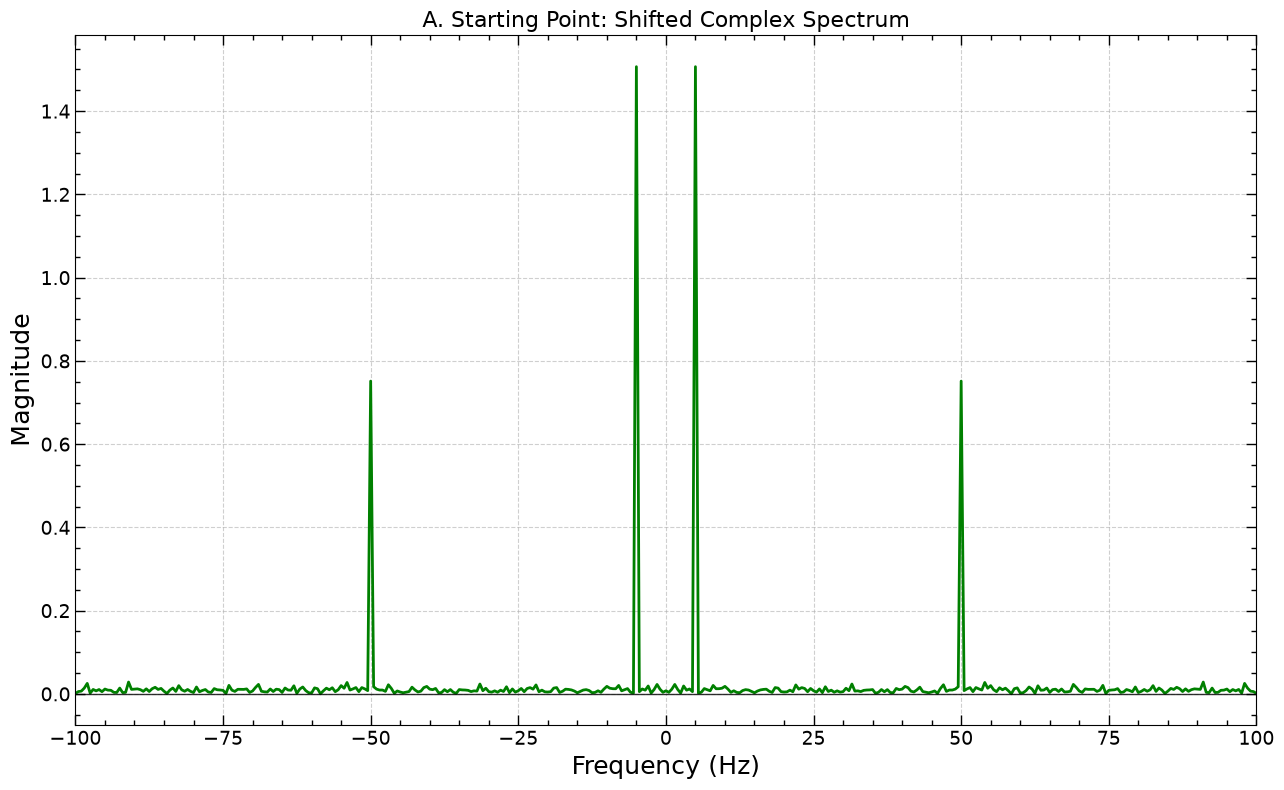

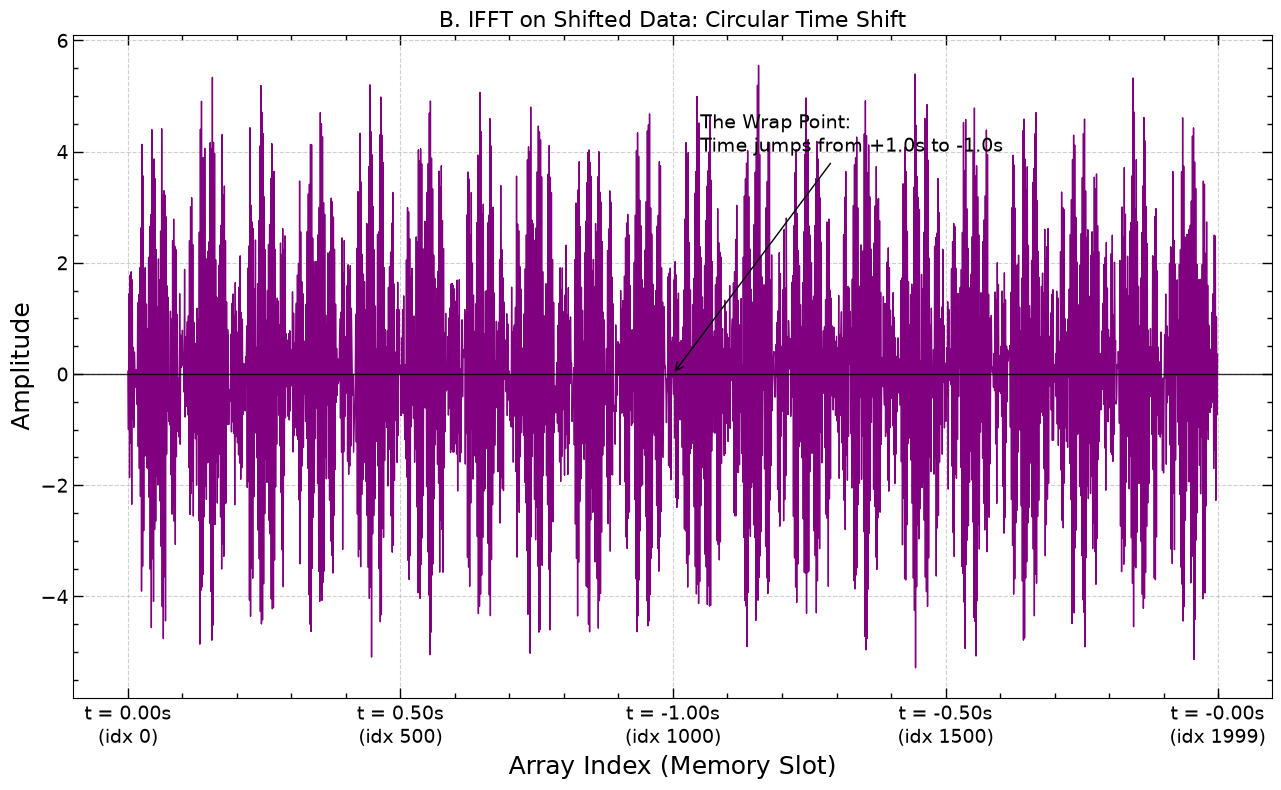

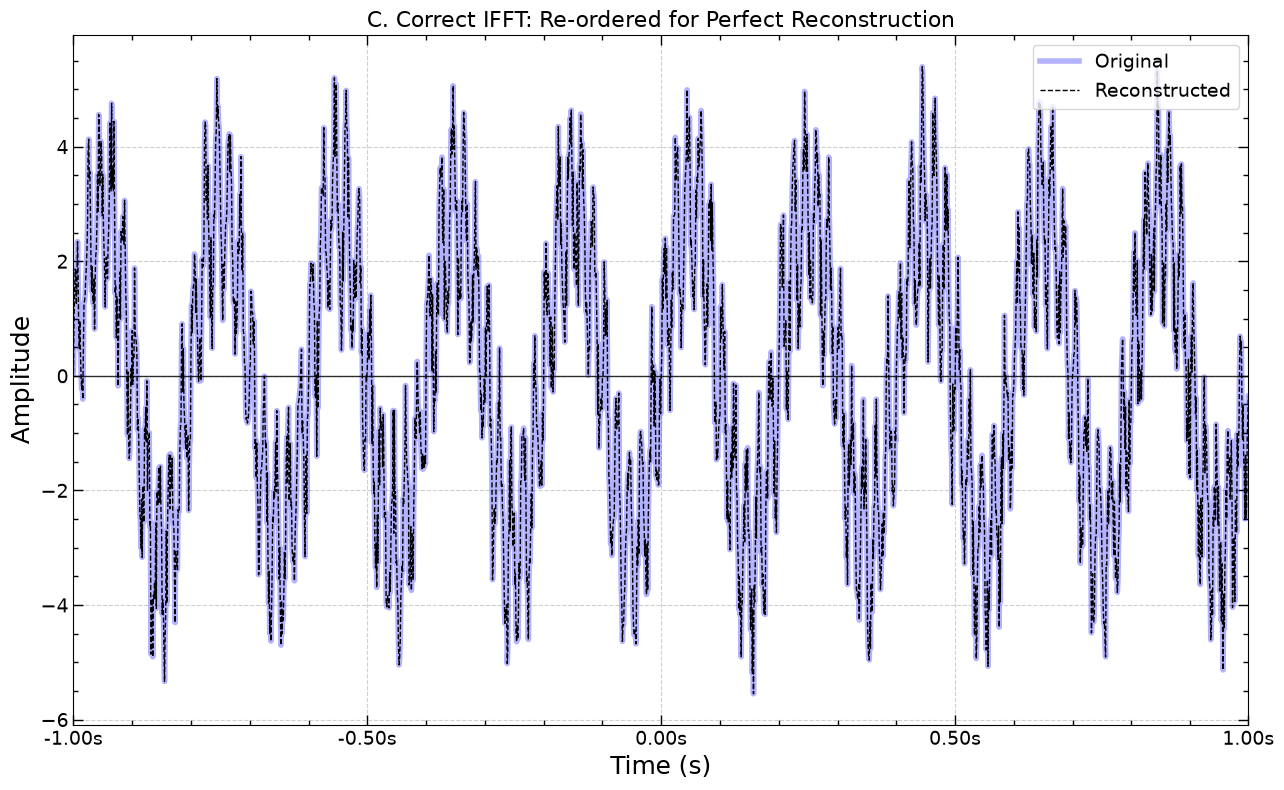

In [2]:
### --- IFFT Tutorial: Centered Time Range ---

# Use the full complex data from the previous cell
# fft_complex_shifted and t are already defined in centered format (-1s to 1s)

# 1. Human-Readable Spectrum (Verification)
fig_a, ax_a = plt.subplots(figsize=(8*1.618, 8))
ax_a.plot(freq_shifted, np.abs(fft_complex_shifted)/N, color='green', linewidth=2)
apply_custom_style(ax_a, 'Frequency (Hz)', 'Magnitude', 'A. Starting Point: Shifted Complex Spectrum')
ax_a.set_xlim(-100, 100)
fig_a.tight_layout()

# 2. The Scrambled IFFT (Directly on Shifted Data)
# This results in a CIRCULAR SHIFT in the time domain.
scrambled_complex = np.fft.ifft(fft_complex_shifted)
reconstructed_scrambled = np.real(scrambled_complex)

fig_b, ax_b = plt.subplots(figsize=(8*1.618, 8))
# Plotting against memory index
ax_b.plot(np.arange(N), reconstructed_scrambled, color='purple', linewidth=1)

# Shift the original centered time vector to match the scrambled memory layout
# t_wrapped[0] will now be 0.0s, and the jump happens at the original signal boundaries
t_wrapped = np.fft.fftshift(t) 

tick_indices2 = [0, N//4, N//2, 3*N//4, N-1]
tick_labels2 = [f"t = {t_wrapped[i]:.2f}s\n(idx {i})" for i in tick_indices2]
ax_b.set_xticks(tick_indices2)
ax_b.set_xticklabels(tick_labels2)

# Highlight the "Jump" at the center (N/2)
# Here, the signal wraps from the end (+1.0s) back to the start (-1.0s)
ax_b.annotate('The Wrap Point:\nTime jumps from +1.0s to -1.0s', 
             xy=(N//2, 0), xytext=(N//2 + 50, 4),
             arrowprops=dict(facecolor='black', arrowstyle='->'), fontsize=14)

apply_custom_style(ax_b, 'Array Index (Memory Slot)', 'Amplitude', 'B. IFFT on Shifted Data: Circular Time Shift')
# ax_b.set_xlim(-50, N + 50)
fig_b.tight_layout()

# 3. The Correct Path (ifftshift -> IFFT)
# Move DC back to index 0
ready_for_ifft = np.fft.ifftshift(fft_complex_shifted)
correct_complex = np.fft.ifft(ready_for_ifft)
reconstructed_clean = np.real(correct_complex)

fig_c, ax_c = plt.subplots(figsize=(8*1.618, 8))
ax_c.plot(t, signal, color='blue', alpha=0.3, linewidth=4, label='Original')
ax_c.plot(t, reconstructed_clean, color='black', linestyle='--', linewidth=1, label='Reconstructed')

# Re-apply standard centered time labels
tick_indices_c = [0, N//4, N//2, 3*N//4, N-1]
tick_labels_c = [f"{t[i]:.2f}s" for i in tick_indices_c]
ax_c.set_xticks([t[i] for i in tick_indices_c])
ax_c.set_xticklabels(tick_labels_c)

apply_custom_style(ax_c, 'Time (s)', 'Amplitude', 'C. Correct IFFT: Re-ordered for Perfect Reconstruction')
ax_c.legend(fontsize=14, loc='upper right')
ax_c.set_xlim(t.min(), t.max())
fig_c.tight_layout()

plt.show()

## Summary of proper `fft` process


| Operation | Goal | Domain |
| :--- | :--- | :--- |
| **`fft`** | Time to Frequency | Result: DC at index 0 |
| **`fftshift`** | DC at index 0 $\to$ Center | For plotting/analysis |
| **`ifftshift`** | DC at Center $\to$ index 0 | Preparing for IFFT |
| **`ifft`** | Frequency to Time | Input: DC at index 0 |

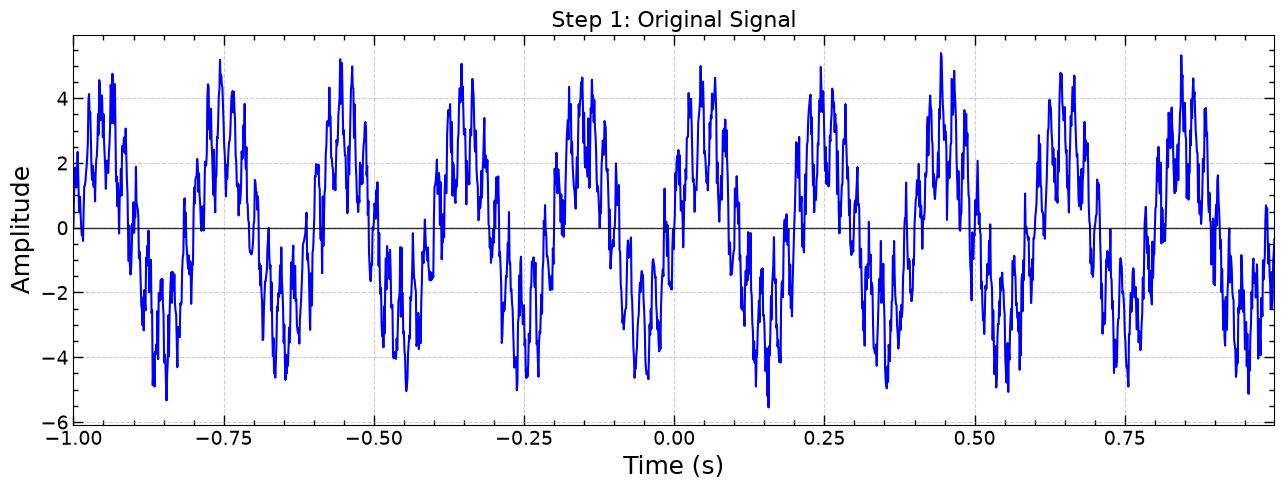

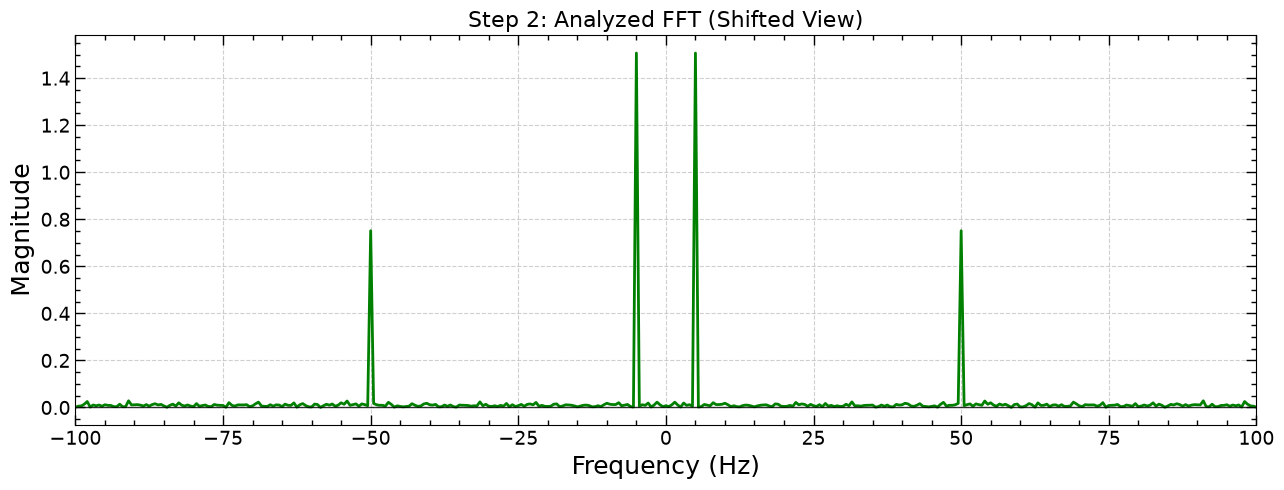

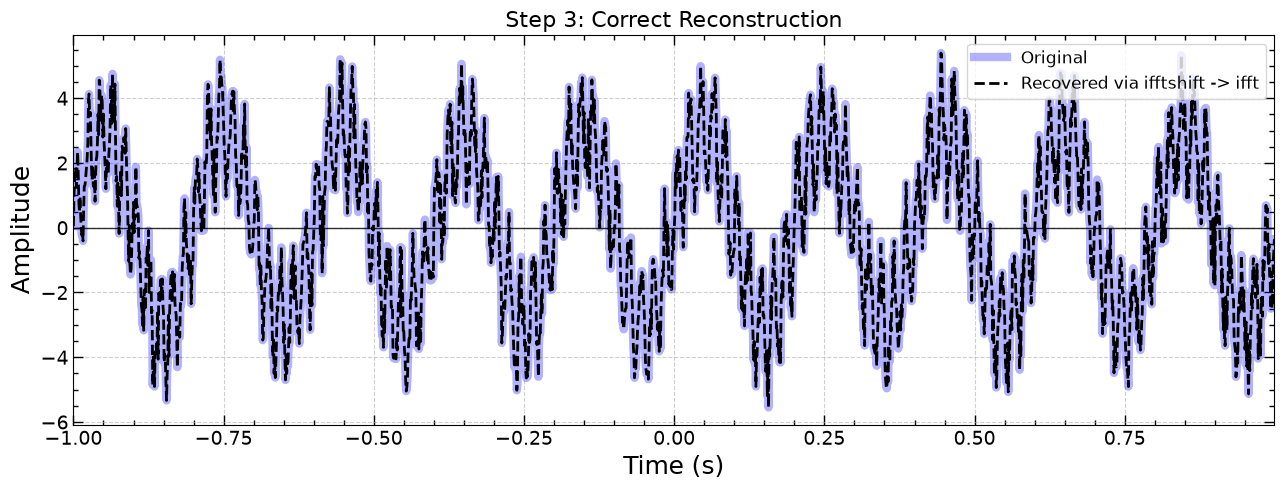

In [3]:
### --- Correct Sequence Plotting ---

# 1. The Starting Signal (Time Domain)
fig_seq1, ax_seq1 = plt.subplots(figsize=(8*1.618, 5))
ax_seq1.plot(t, signal, color='blue', linewidth=1.5)
apply_custom_style(ax_seq1, 'Time (s)', 'Amplitude', 'Step 1: Original Signal')
ax_seq1.set_xlim(t.min(), t.max())
fig_seq1.tight_layout()

# 2. The Analyzed Spectrum (Frequency Domain)
# Using the centered complex data you already defined
fig_seq2, ax_seq2 = plt.subplots(figsize=(8*1.618, 5))
ax_seq2.plot(freq_shifted, np.abs(fft_complex_shifted)/N, color='green', linewidth=2)
apply_custom_style(ax_seq2, 'Frequency (Hz)', 'Magnitude', 'Step 2: Analyzed FFT (Shifted View)')
ax_seq2.set_xlim(-100, 100) # Zoomed for visibility
fig_seq2.tight_layout()

# 3. The Reconstructed Signal (Return to Time Domain)
# This performs the 'ifftshift -> ifft' sequence you requested
fig_seq3, ax_seq3 = plt.subplots(figsize=(8*1.618, 5))

# Math performed inline as requested: Shift back, then IFFT
reconstructed_signal = np.real(np.fft.ifft(np.fft.ifftshift(fft_complex_shifted)))

ax_seq3.plot(t, signal, color='blue', alpha=0.3, linewidth=6, label='Original')
ax_seq3.plot(t, reconstructed_signal, color='black', linestyle='--', linewidth=2, label='Recovered via ifftshift -> ifft')

apply_custom_style(ax_seq3, 'Time (s)', 'Amplitude', 'Step 3: Correct Reconstruction')
ax_seq3.legend(loc='upper right', fontsize=12)
ax_seq3.set_xlim(t.min(), t.max())
fig_seq3.tight_layout()

plt.show()

## Frequency filtering

### Analytic Approach ###
Consider a signal $f(t)$ as a function of time which is just the sum of two sine curves with different frequencies:
$$s(t) = A_1 \sin(2\pi f_1 t) + A_2 \sin(2\pi f_2 t)$$
where $f_1$ = 5 Hz, $f_2$ = 50 Hz, $A_1$ = 3, $A_2$ = 1.5 (amplitudes unitless).

The Fourier transform $S(f)$ yields a plot of the amplitudes of the frequencies contained in the signal. Analytically, the Fourier transform is given by:
$$S(f) = \int_{-\infty}^{\infty} s(t) e^{-i 2\pi f t} dt$$
In the code, np.fft.fft computes the discrete version (DFT). It results in an array where the magnitude $|S(f)|$ shows spikes at $\pm 5$ Hz and $\pm 50$ Hz.

Next, we can apply a filter in the Fourier domain.  Consider the square filter $H(f)$, sometimes called the "rect" or "top-hat" function. Because the filter is multiplied by the Fourier transform, it acts a low-pass frequency filter which keeps the magnitude of the 5 Hz frequency component but zeroes out the 50 Hz frequency component.  The inverse Fourier transform therefore yields a sine curve with frequency 5 Hz (and the 50 Hz frequency is removed).

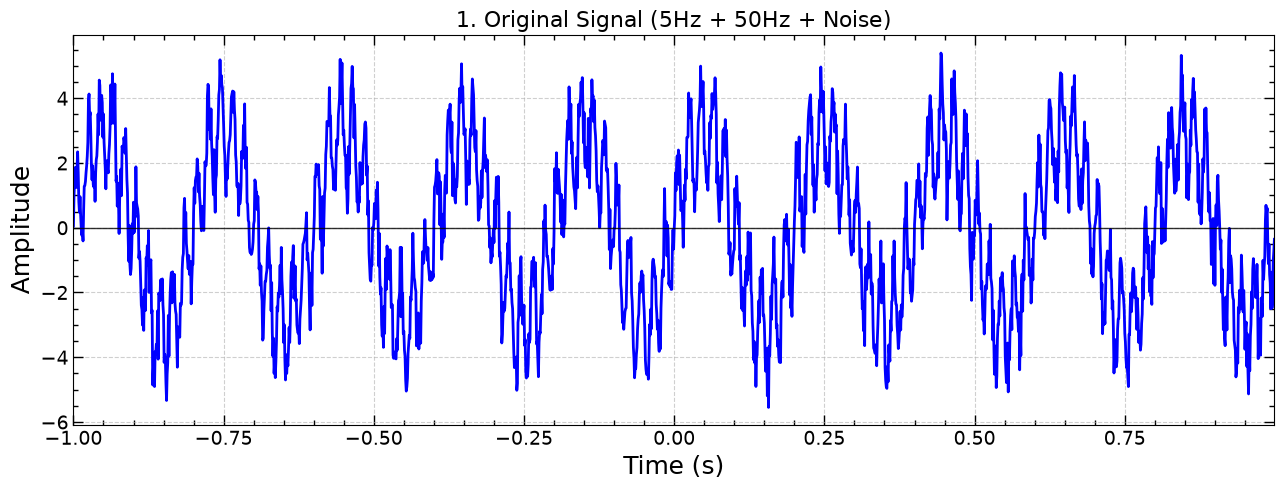

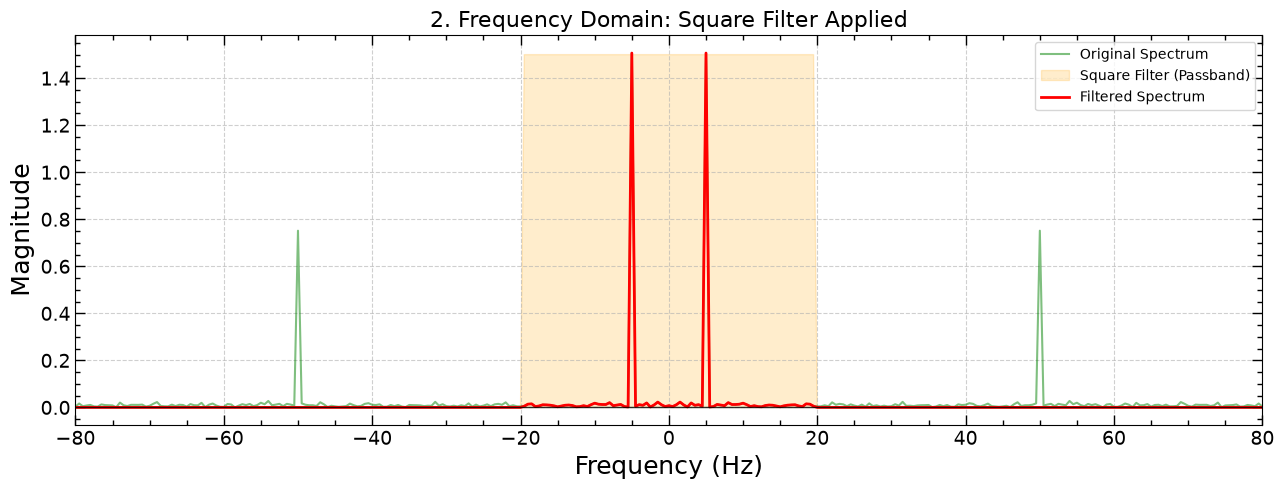

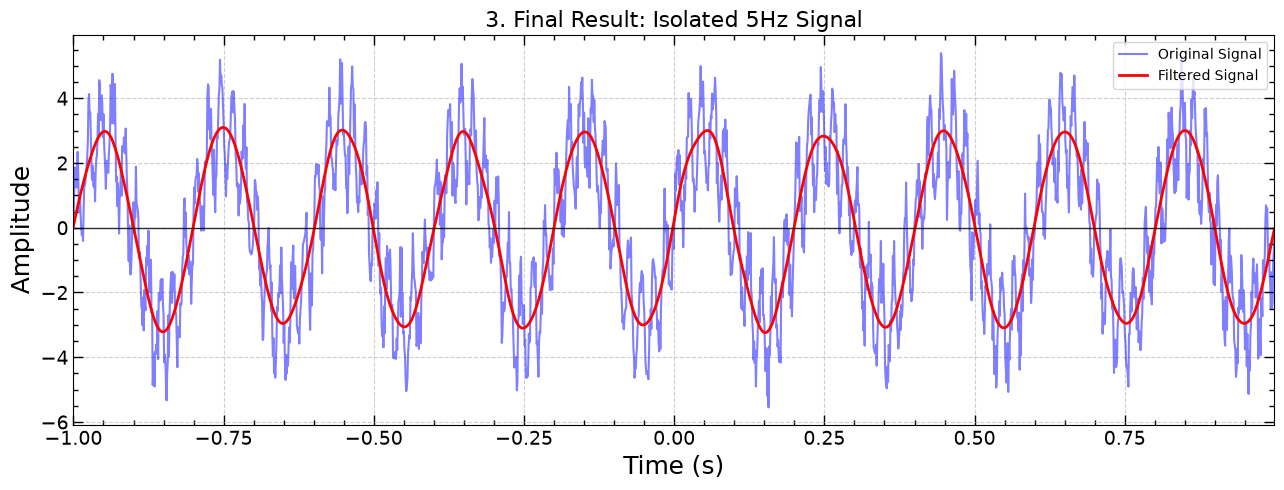

In [4]:
# --- Sequence: Low-Pass Filtering to Isolate 5Hz Signal ---

# 1. Step 1: Original Signal (Noisy)
fig_f1, ax_f1 = plt.subplots(figsize=(8*1.618, 5))
ax_f1.plot(t, signal, color='blue', linewidth=2, label='Original Noisy Signal')
apply_custom_style(ax_f1, 'Time (s)', 'Amplitude', '1. Original Signal (5Hz + 50Hz + Noise)')
ax_f1.set_xlim(t.min(), t.max())
fig_f1.tight_layout()

# 2. Step 2: Frequency Domain Square Filter
# We create a mask that is 1.0 between -20Hz and 20Hz, and 0.0 elsewhere
# This will pass 5Hz and block 50Hz.
square_filter = np.zeros_like(freq_shifted)
square_filter[np.abs(freq_shifted) < 20] = 1.0

# Apply the filter to the COMPLEX shifted data
filtered_fft_complex = fft_complex_shifted * square_filter

fig_f2, ax_f2 = plt.subplots(figsize=(8*1.618, 5))
# Plot the magnitude of the spectrum
ax_f2.plot(freq_shifted, np.abs(fft_complex_shifted)/N, color='green', alpha=0.5, label='Original Spectrum')
# Plot the Square Filter (scaled for visibility)
ax_f2.fill_between(freq_shifted, 0, square_filter * (amp1/2), color='orange', alpha=0.2, label='Square Filter (Passband)')
# Plot the resulting filtered spectrum
ax_f2.plot(freq_shifted, np.abs(filtered_fft_complex)/N, color='red', linewidth=2, label='Filtered Spectrum')

apply_custom_style(ax_f2, 'Frequency (Hz)', 'Magnitude', '2. Frequency Domain: Square Filter Applied')
ax_f2.set_xlim(-80, 80)
ax_f2.legend(loc='upper right')
fig_f2.tight_layout()

# 3. Step 3: Reconstructed 5Hz Signal
# Sequence: ifftshift -> ifft -> real
reconstructed_5hz = np.real(np.fft.ifft(np.fft.ifftshift(filtered_fft_complex)))

fig_f3, ax_f3 = plt.subplots(figsize=(8*1.618, 5))
ax_f3.plot(t, signal, color='blue', alpha=0.5, label='Original Signal')
ax_f3.plot(t, reconstructed_5hz, color='red', linewidth=2, label='Filtered Signal')

apply_custom_style(ax_f3, 'Time (s)', 'Amplitude', '3. Final Result: Isolated 5Hz Signal')
ax_f3.set_xlim(t.min(), t.max())
ax_f3.legend(loc='upper right')
fig_f3.tight_layout()

plt.show()